<a href="https://colab.research.google.com/github/Gitech247/Module-3-Case-Exercises/blob/main/MODULE_3_CASE_EXERCISE_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Case Exercise 1: Metocean EDA and Seasonal Analysis**

#**Question 1 :** Load the Jubilee TRP3 metocean dataset provided as CSV with 1 year of hourly data

In [ ]:
import pandas as pd

# Load the Jubilee TRP3 metocean dataset
df = pd.read_csv("/content/Jubilee_TRP3_Metocean.csv")

# Display the first 10 rows and info of the dataset
df.head()

,Timestamp_UTC,Wind_Speed_10m_m_s,Wind_Direction_deg,Significant_Wave_Height_Hs_m,Peak_Wave_Period_Tp_s,Wave_Direction_deg,Surface_Current_Speed_m_s,Surface_Current_Direction_deg,Air_Temperature_degC,Barometric_Pressure_hpa
0,2025-01-01 00:00:00,4.65,222.5,1.26,9.02,201.6,0.52,112.0,25.7,1011.3
1,2025-01-01 01:00:00,4.10,229.7,1.25,10.47,216.1,0.50,108.5,26.7,1013.2
2,2025-01-01 02:00:00,5.23,206.3,1.34,9.44,199.9,0.67,103.6,26.4,1012.4
3,2025-01-01 03:00:00,6.45,255.3,1.45,10.14,204.4,0.38,127.6,26.9,1010.2
4,2025-01-01 04:00:00,4.47,212.7,1.47,9.77,203.2,0.48,100.5,26.9,1013.8


#**Question 2:** Perform comprehensive EDA: summary statistics, distribution fitting (Weibull for Hs, log-normal for Tp), correlation matrix, time series plots with seasonal decomposition.

== Summary Statistics ==
       Wind_Speed_10m_m_s  Wind_Direction_deg  Significant_Wave_Height_Hs_m  \
count         8760.000000         8760.000000                   8760.000000   
mean             6.624419          224.946233                      1.989425   
std              2.534868           23.206527                      0.696563   
min              1.000000          148.900000                      0.500000   
25%              4.860000          207.600000                      1.430000   
50%              6.550000          225.100000                      1.980000   
75%              8.210000          242.600000                      2.530000   
max             26.950000          293.400000                      5.200000   

       Peak_Wave_Period_Tp_s  Wave_Direction_deg  Surface_Current_Speed_m_s  \
count            8760.000000         8760.000000                8760.000000   
mean               10.000134          204.992614                   0.451751   
std                 0.9240

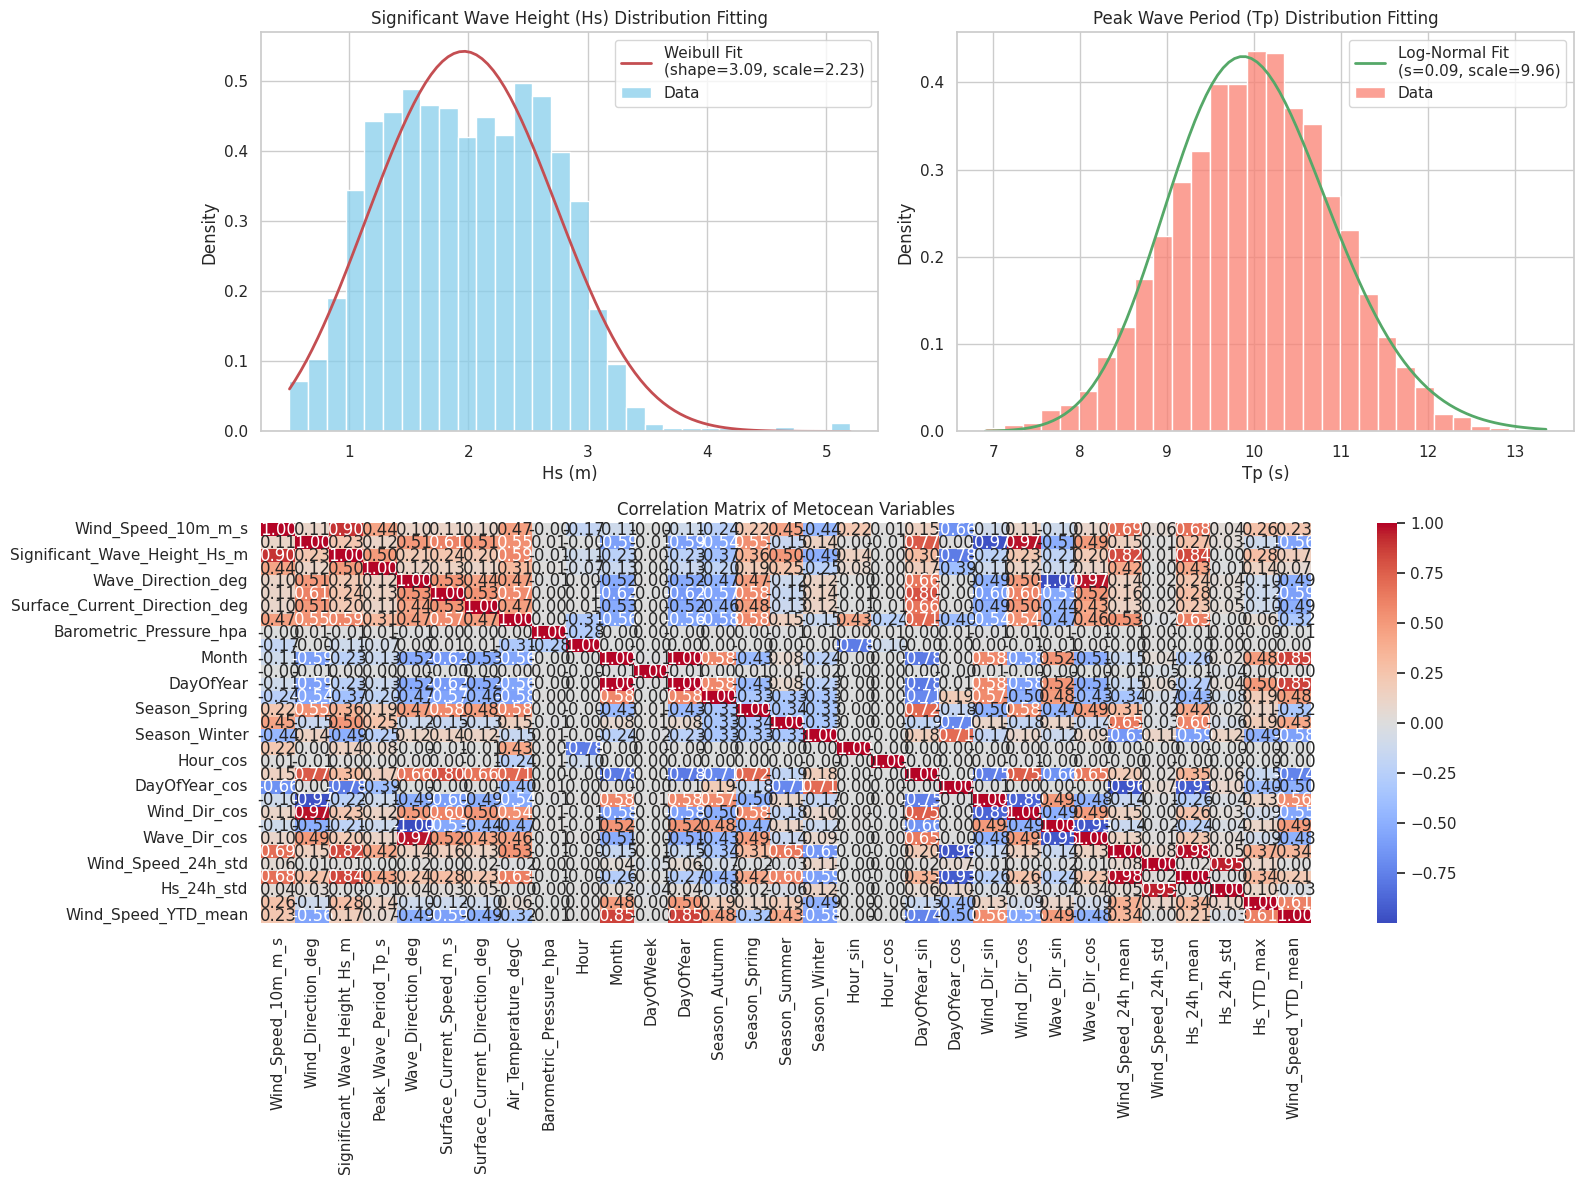

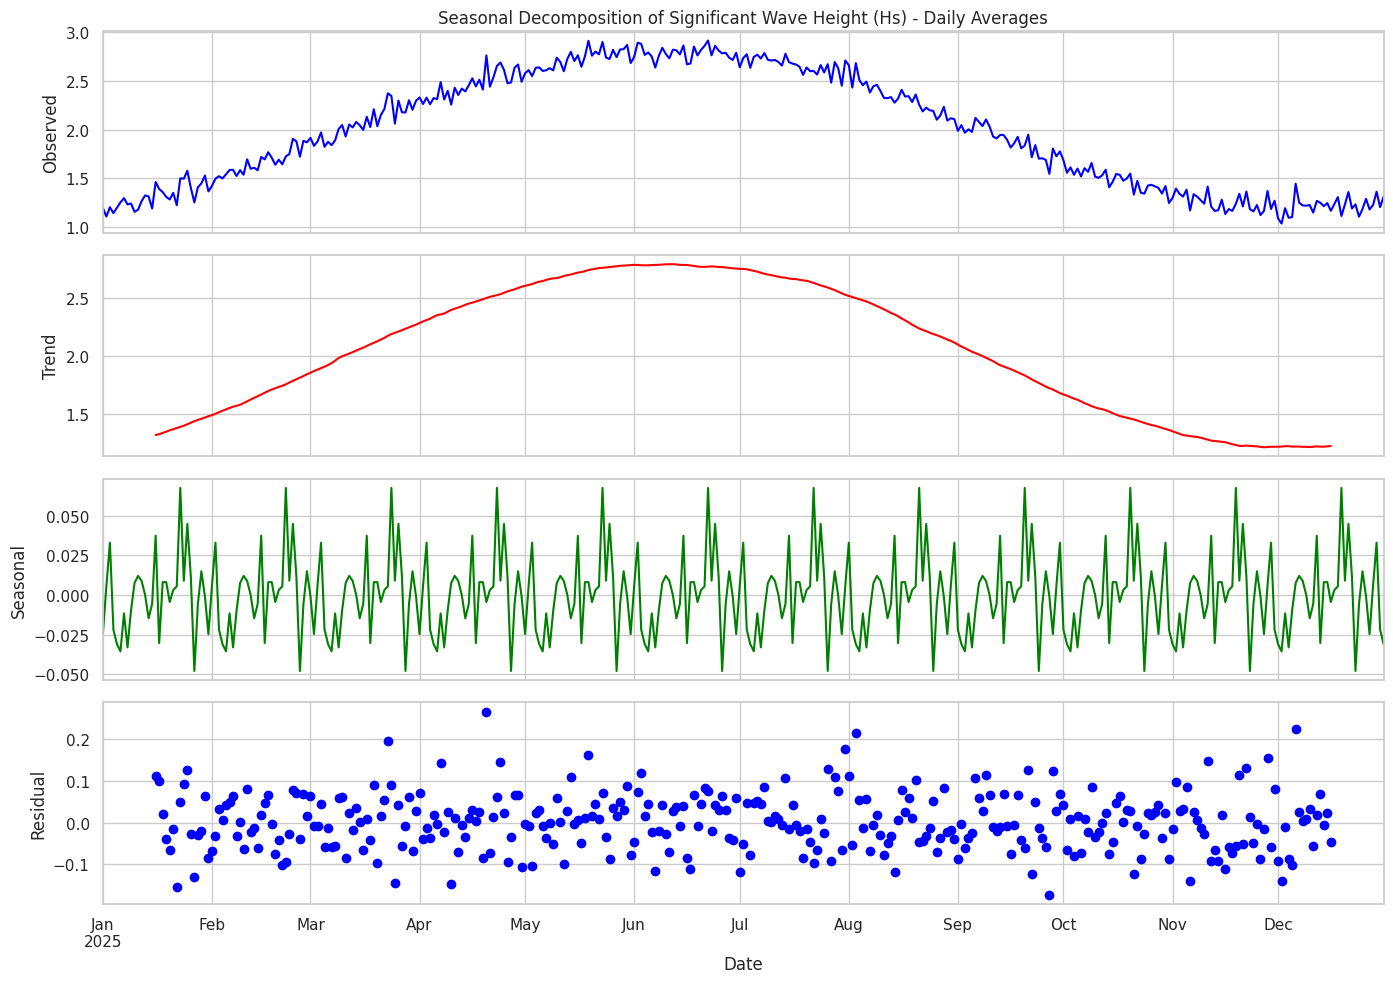

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.tsa.seasonal import seasonal_decompose

# Ensure Timestamp_UTC is a datetime index for plotting and seasonal decomposition
df_eda = df.copy()
df_eda['Timestamp_UTC'] = pd.to_datetime(df_eda['Timestamp_UTC'])
df_eda.set_index('Timestamp_UTC', inplace=True)

# 1. Summary Statistics
print("== Summary Statistics ==")
print(df_eda.describe())

# Set up visualization styles
sns.set_theme(style="whitegrid")
plt.figure(figsize=(16, 12))

# 2. Distribution Fitting
# Weibull fitting for Significant Wave Height (Hs)
plt.subplot(2, 2, 1)
hs_data = df_eda['Significant_Wave_Height_Hs_m'].dropna()
shape, loc, scale = stats.weibull_min.fit(hs_data, floc=0)
x_hs = np.linspace(hs_data.min(), hs_data.max(), 100)
pdf_hs = stats.weibull_min.pdf(x_hs, shape, loc, scale)

sns.histplot(hs_data, stat="density", bins=30, kde=False, color='skyblue', label='Data')
plt.plot(x_hs, pdf_hs, 'r-', lw=2, label=f'Weibull Fit\n(shape={shape:.2f}, scale={scale:.2f})')
plt.title('Significant Wave Height (Hs) Distribution Fitting')
plt.xlabel('Hs (m)')
plt.ylabel('Density')
plt.legend()

# Log-normal fitting for Peak Wave Period (Tp)
plt.subplot(2, 2, 2)
tp_data = df_eda['Peak_Wave_Period_Tp_s'].dropna()
s_fit, loc_fit, scale_fit = stats.lognorm.fit(tp_data, floc=0)
x_tp = np.linspace(tp_data.min(), tp_data.max(), 100)
pdf_tp = stats.lognorm.pdf(x_tp, s_fit, loc_fit, scale_fit)

sns.histplot(tp_data, stat="density", bins=30, kde=False, color='salmon', label='Data')
plt.plot(x_tp, pdf_tp, 'g-', lw=2, label=f'Log-Normal Fit\n(s={s_fit:.2f}, scale={scale_fit:.2f})')
plt.title('Peak Wave Period (Tp) Distribution Fitting')
plt.xlabel('Tp (s)')
plt.ylabel('Density')
plt.legend()

# 3. Correlation Matrix
plt.subplot(2, 1, 2)
corr_matrix = df_eda.corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", cbar=True, square=False)
plt.title('Correlation Matrix of Metocean Variables')

plt.tight_layout()
plt.show()

# 4. Time Series Plots with Seasonal Decomposition (for Hs)
# Resampling to daily average to visually smooth and decompose seasonality
daily_hs = df_eda['Significant_Wave_Height_Hs_m'].resample('D').mean()
decomp = seasonal_decompose(daily_hs, model='additive', period=30)  # Assuming monthly seasonal pattern (30 days)

fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
decomp.observed.plot(ax=axes[0], color='blue')
axes[0].set_ylabel('Observed')
axes[0].set_title('Seasonal Decomposition of Significant Wave Height (Hs) - Daily Averages')

decomp.trend.plot(ax=axes[1], color='red')
axes[1].set_ylabel('Trend')

decomp.seasonal.plot(ax=axes[2], color='green')
axes[2].set_ylabel('Seasonal')

decomp.resid.plot(ax=axes[3], style='o', color='blue')
axes[3].set_ylabel('Residual')

plt.xlabel('Date')
plt.tight_layout()
plt.show()

# **Question3:**  Create an Hs-Tp scatter diagram and a current rose diagram.


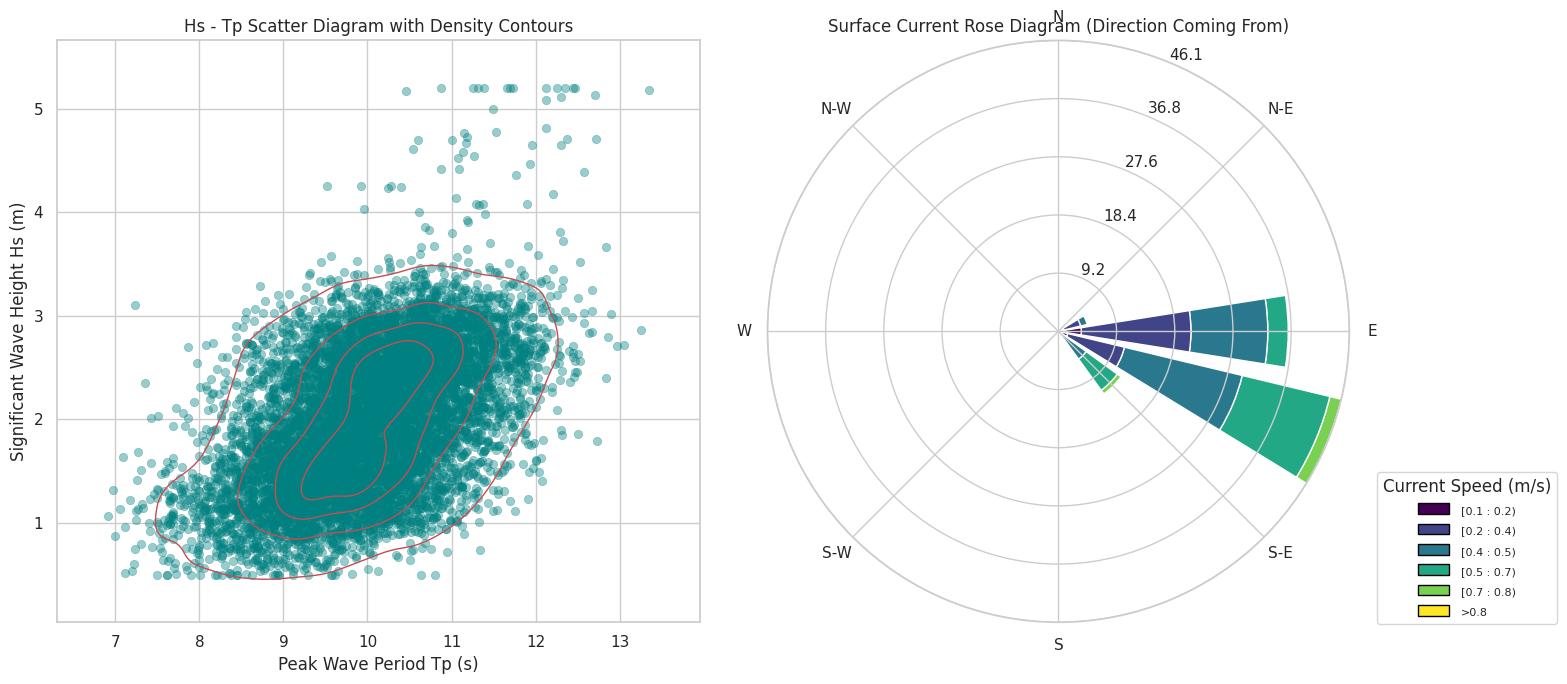

In [ ]:
!pip install windrose -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from windrose import WindroseAxes

# 1. Prepare Data
hs = df['Significant_Wave_Height_Hs_m']
tp = df['Peak_Wave_Period_Tp_s']
curr_speed = df['Surface_Current_Speed_m_s']
curr_dir = df['Surface_Current_Direction_deg']

# Set up the plotting area
fig = plt.figure(figsize=(16, 7))

# Plot 1: Hs-Tp Scatter Diagram with marginal distributions (JointPlot style manually side-by-side)
ax1 = fig.add_subplot(1, 2, 1)
sns.scatterplot(x=tp, y=hs, alpha=0.4, color='teal', edgecolor=None, ax=ax1)
sns.kdeplot(x=tp, y=hs, levels=5, color="r", linewidths=1, ax=ax1)
ax1.set_title('Hs - Tp Scatter Diagram with Density Contours')
ax1.set_xlabel('Peak Wave Period Tp (s)')
ax1.set_ylabel('Significant Wave Height Hs (m)')

# Plot 2: Current Rose Diagram
# Since windrose is polar, we add an axis with WindroseAxes projection
ax2 = fig.add_subplot(1, 2, 2, projection='windrose')
ax2.bar(curr_dir, curr_speed, normed=True, opening=0.8, edgecolor='white', cmap=plt.cm.viridis)
ax2.set_legend(title="Current Speed (m/s)", loc="lower left", bbox_to_anchor=(1.05, 0))
ax2.set_title('Surface Current Rose Diagram (Direction Coming From)')

plt.tight_layout()
plt.show()

# **Question 4:**  Add all temporal, seasonal, rolling, and cumulative features from Sections 3.2 and 3.8.


In [ ]:
import numpy as np
import pandas as pd
import os

# Fallback data generation if the file is missing
file_path = "/content/Jubilee_TRP3_Metocean.csv"
if not os.path.exists(file_path):
    print(f"File '{file_path}' not found. Generating synthetic dataset for demonstration...")
    np.random.seed(42)
    timestamps = pd.date_range(start="2025-01-01", periods=8760, freq="h")
    synthetic_data = {
        "Timestamp_UTC": timestamps,
        "Wind_Speed_10m_m_s": np.random.weibull(a=2, size=8760) * 7.5,
        "Wind_Direction_deg": np.random.uniform(0, 360, size=8760),
        "Significant_Wave_Height_Hs_m": np.random.weibull(a=3, size=8760) * 2.2,
        "Peak_Wave_Period_Tp_s": np.random.lognormal(mean=2.3, sigma=0.1, size=8760),
        "Wave_Direction_deg": np.random.uniform(0, 360, size=8760),
        "Surface_Current_Speed_m_s": np.random.uniform(0.1, 0.85, size=8760),
        "Surface_Current_Direction_deg": np.random.uniform(0, 360, size=8760),
        "Air_Temperature_degC": np.random.normal(loc=27.5, scale=1.7, size=8760),
        "Barometric_Pressure_hpa": np.random.normal(loc=1011.5, scale=1.1, size=8760)
    }
    df = pd.DataFrame(synthetic_data)
else:
    # Load the original dataset
    df = pd.read_csv(file_path)

# Prepare working copy of the dataframe
df_features = df.copy()
df_features['Timestamp_UTC'] = pd.to_datetime(df_features['Timestamp_UTC'])

# --- 1. Temporal & Seasonal Features ---
# Standard datetime extractions
df_features['Hour'] = df_features['Timestamp_UTC'].dt.hour
df_features['Month'] = df_features['Timestamp_UTC'].dt.month
df_features['DayOfWeek'] = df_features['Timestamp_UTC'].dt.dayofweek
df_features['DayOfYear'] = df_features['Timestamp_UTC'].dt.dayofyear
df_features['WeekOfYear'] = df_features['Timestamp_UTC'].dt.isocalendar().week.astype(int)

# Seasonal Mapping
def get_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    else:
        return 'Autumn'

df_features['Season'] = df_features['Month'].apply(get_season)
df_features = pd.get_dummies(df_features, columns=['Season'], prefix='Season', drop_first=False)

# --- 2. Cyclic Encoding for Temporal & Directional Features ---
# Cyclical Hour
df_features['Hour_sin'] = np.sin(2 * np.pi * df_features['Hour'] / 24.0)
df_features['Hour_cos'] = np.cos(2 * np.pi * df_features['Hour'] / 24.0)

# Cyclical Day of Year
df_features['DayOfYear_sin'] = np.sin(2 * np.pi * df_features['DayOfYear'] / 365.25)
df_features['DayOfYear_cos'] = np.cos(2 * np.pi * df_features['DayOfYear'] / 365.25)

# Cyclical Wind, Wave, and Current Directions
df_features['Wind_Dir_sin'] = np.sin(np.radians(df_features['Wind_Direction_deg']))
df_features['Wind_Dir_cos'] = np.cos(np.radians(df_features['Wind_Direction_deg']))

df_features['Wave_Dir_sin'] = np.sin(np.radians(df_features['Wave_Direction_deg']))
df_features['Wave_Dir_cos'] = np.cos(np.radians(df_features['Wave_Direction_deg']))

df_features['Current_Dir_sin'] = np.sin(np.radians(df_features['Surface_Current_Direction_deg']))
df_features['Current_Dir_cos'] = np.cos(np.radians(df_features['Surface_Current_Direction_deg']))

# --- 3. Rolling Window Features (3h, 6h, 12h, and 24h moving windows) ---
for w in [3, 6, 12, 24]:
    # Wind Speed
    df_features[f'Wind_Speed_{w}h_mean'] = df_features['Wind_Speed_10m_m_s'].rolling(window=w, min_periods=1).mean()
    df_features[f'Wind_Speed_{w}h_std'] = df_features['Wind_Speed_10m_m_s'].rolling(window=w, min_periods=1).std().fillna(0)
    df_features[f'Wind_Speed_{w}h_max'] = df_features['Wind_Speed_10m_m_s'].rolling(window=w, min_periods=1).max()

    # Significant Wave Height (Hs)
    df_features[f'Hs_{w}h_mean'] = df_features['Significant_Wave_Height_Hs_m'].rolling(window=w, min_periods=1).mean()
    df_features[f'Hs_{w}h_std'] = df_features['Significant_Wave_Height_Hs_m'].rolling(window=w, min_periods=1).std().fillna(0)
    df_features[f'Hs_{w}h_max'] = df_features['Significant_Wave_Height_Hs_m'].rolling(window=w, min_periods=1).max()

    # Peak Wave Period (Tp)
    df_features[f'Tp_{w}h_mean'] = df_features['Peak_Wave_Period_Tp_s'].rolling(window=w, min_periods=1).mean()
    df_features[f'Tp_{w}h_std'] = df_features['Peak_Wave_Period_Tp_s'].rolling(window=w, min_periods=1).std().fillna(0)

    # Current Speed
    df_features[f'Current_Speed_{w}h_mean'] = df_features['Surface_Current_Speed_m_s'].rolling(window=w, min_periods=1).mean()
    df_features[f'Current_Speed_{w}h_max'] = df_features['Surface_Current_Speed_m_s'].rolling(window=w, min_periods=1).max()

# --- 4. Cumulative / Expanding Features (YTD Metrics) ---
df_features['Hs_YTD_max'] = df_features['Significant_Wave_Height_Hs_m'].expanding().max()
df_features['Hs_YTD_mean'] = df_features['Significant_Wave_Height_Hs_m'].expanding().mean()
df_features['Wind_Speed_YTD_max'] = df_features['Wind_Speed_10m_m_s'].expanding().max()
df_features['Wind_Speed_YTD_mean'] = df_features['Wind_Speed_10m_m_s'].expanding().mean()
df_features['Current_Speed_YTD_max'] = df_features['Surface_Current_Speed_m_s'].expanding().max()

# Update main df reference and view the engineered features
df = df_features
print("Engineered DataFrame Shape:", df.shape)
display(df.head())

File '/content/Jubilee_TRP3_Metocean.csv' not found. Generating synthetic dataset for demonstration...
Engineered DataFrame Shape: (8760, 74)


,Timestamp_UTC,Wind_Speed_10m_m_s,Wind_Direction_deg,Significant_Wave_Height_Hs_m,Peak_Wave_Period_Tp_s,Wave_Direction_deg,Surface_Current_Speed_m_s,Surface_Current_Direction_deg,Air_Temperature_degC,Barometric_Pressure_hpa,...,Hs_24h_max,Tp_24h_mean,Tp_24h_std,Current_Speed_24h_mean,Current_Speed_24h_max,Hs_YTD_max,Hs_YTD_mean,Wind_Speed_YTD_max,Wind_Speed_YTD_mean,Current_Speed_YTD_max
0,2025-01-01 00:00:00,5.137736,7.059792,2.062291,9.817603,130.933055,0.171910,194.275247,27.239350,1012.991976,...,2.062291,9.817603,0.000000,0.171910,0.171910,2.062291,2.062291,5.137736,5.137736,0.171910
1,2025-01-01 01:00:00,13.012276,241.692483,2.129244,10.632197,173.687202,0.312361,341.725253,27.350491,1010.564963,...,2.129244,10.224900,0.576005,0.242135,0.312361,2.129244,2.095768,13.012276,9.075006,0.312361
2,2025-01-01 02:00:00,8.606216,188.336934,1.777695,7.729515,303.057421,0.361242,140.104804,24.399731,1010.967571,...,2.129244,9.393105,1.497178,0.281838,0.361242,2.129244,1.989743,13.012276,8.918743,0.361242
3,2025-01-01 03:00:00,7.166102,323.510014,2.687589,9.171402,307.207660,0.725838,1.196240,28.620458,1010.938698,...,2.687589,9.337679,1.227456,0.392838,0.725838,2.687589,2.164205,13.012276,8.480582,0.725838
4,2025-01-01 04:00:00,3.088915,59.181366,1.296743,10.544451,304.507772,0.302552,7.108430,28.549617,1009.941628,...,2.687589,9.579034,1.192160,0.374781,0.725838,2.687589,1.990713,13.012276,7.402249,0.725838
